In [8]:
from ugot import ugot

got = ugot.UGOT()
got.initialize("192.168.88.1")
got.show_light_rgb([1, 2, 3], 255, 255, 255)

192.168.88.1:50051


In [9]:
got.load_models(['face_recognition'])

True

In [64]:
got.play_sound("chicken")

# OpenCV
OpenCV (Open Source Computer Vision Library) is a free, open-source software library with hundreds of real-time computer vision and machine learning algorithms. It helps computers process, analyze, and understand digital images and video streams

1. First, check that it is installed properly:

In [12]:
import cv2
print(cv2.__version__)

5.0.0


2. Open the camera:

In [ ]:
cap = cv2.VideoCapture(0)

The 0 means: Use camera number 0, usually your laptop's built-in webcam.

If you have multiple cameras:
```
cap = cv2.VideoCapture(1)
```
might access the second camera

3. Next, lets capture an image from the camera:

In [13]:
import cv2

cap = cv2.VideoCapture(0)
ret, frame = cap.read()
cap.release()

print(ret)
print(frame.shape)

True
(480, 640, 3)


The line `ret, frame = cap.read()` gives us two things:
- ret: Was an image successfully captured? (True/False)
- frame: The actual camera image

Note: OpenCV stores images as BGR, while most image processing libraries expects images in RGB format, so you need to convert it with: 
```
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
``` 

In [52]:
import cv2
from IPython.display import display, clear_output
from PIL import Image
import time

cap = cv2.VideoCapture(0)

try:
    while True:
        ret, frame = cap.read()

        if not ret:
            print("Could not read camera")
            break

        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        display(Image.fromarray(frame))
        clear_output(wait=True)

except KeyboardInterrupt:
    print("Camera stopped")

finally:
    cap.release()

Camera stopped


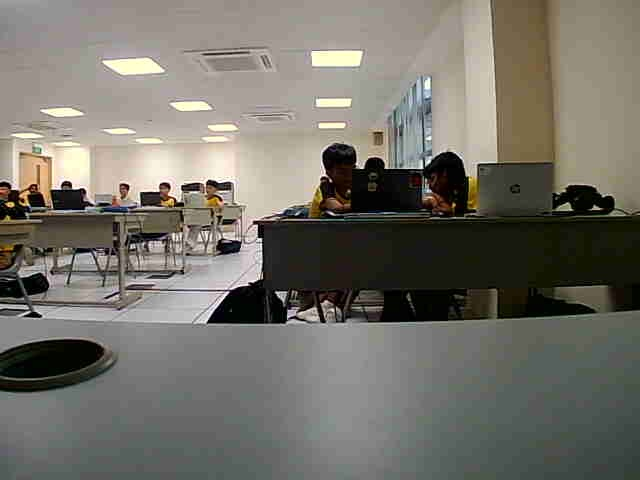

Done


In [57]:
import cv2
import numpy as np
from IPython.display import display, Image, clear_output

got.open_camera()
try:
    while True:
        # Grab the latest camera frame as raw bytes
        frame = got.read_camera_data()

        # Decode the bytes into an OpenCV image array
        nparr = np.frombuffer(frame, np.uint8)
        img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

        face_result = got.get_face_recognition_total_info()

        for face in face_result:
            name, center_x, center_y, height, width, area = face

            # Calculate bounding-box corners
            left = int(center_x - width / 2)
            top = int(center_y - height / 2)

            right = int(center_x + width / 2)
            bottom = int(center_y + height / 2)

            # Draw bounding box
            cv2.rectangle(img, (left, top), (right, bottom), (0, 255, 0), 2 )

            # Draw person's name
            cv2.putText(img, name, (left, top - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

        # Encode the annotated frame as JPEG and display it inline in the notebook
        _, jpeg = cv2.imencode(".jpg", img)
        clear_output(wait=True)
        display(Image(data=jpeg.tobytes()))

except KeyboardInterrupt:
    print("Done")
    got.mecanum_stop()

In [10]:
got.face_recognition_get_all_names() # Check for registered faces

['good man',
 'dexter',
 'jerome',
 'arjun',
 'ananya',
 'coley',
 'Ryan',
 'Coley',
 'shriash']

In [4]:
got.face_recognition_add_name('Arjun') # Add a face

3 seconds until taking a photo
2 seconds until taking a photo
1 seconds until taking a photo
Taking a photo...
Face [Arjun] registered successfully



In [12]:
got.get_face_recognition_total_info() # Get info of detected face

[['arjun', 298.0, 147.0, 102, 80, 8160]]

In [ ]:
face = got.get_face_recognition_total_info()

while True:
  face = got.get_face_recognition_total_info()
  if face:
    if face[0][0] == 'Arjun':
      got.play_sound("elephant", True)
  else:
    got.play_sound("chicken", True)